# OpenMapTiles layers and classes in the crops

Effort to categorize and hand-label layers, classes, and subclasses as semantic labels

In [1]:
import collections, gzip, json, sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

sys.path.insert(0, "..")
from data_preprocess.create_coco_osm import PARTS, SKIP, label_for, make_to_px
%matplotlib inline

CROPS = Path("../crops_flushing")
N_COLOR_CROPS = 300   # crops sampled for colours (all crops are used for counts)
TOP_N = 40            # (layer, class, geometry) combinations shown in the charts
TOP_COLORS = 3
GEOM_COLORS = {"polygon": "#2a78d6", "line": "#eb6834", "point": "#1baf7a"}   # validated categorical slots 1-3

files = sorted(CROPS.glob("*.geojson.gz"))
print(len(files), "crops")

{'path': [('transportation', 'path', 'cycleway', 'line'), ('transportation', 'path', 'bridleway', 'line'), ('transportation', 'path', 'path', 'line'), ('transportation', 'path', 'platform', 'line'), ('transportation', 'path', 'corridor', 'line'), ('transportation', 'track', None, 'line'), ('transportation', 'path', 'footway', 'line'), ('transportation', 'path', 'steps', 'line'), ('transportation', 'path', 'pedestrian', 'line')], 'park': [('park', 'wildlife_refuge', None, 'polygon'), ('park', 'National Recreation Area', None, 'polygon'), ('park', 'protected_area', None, 'polygon'), ('park', 'nature_reserve', None, 'polygon'), ('landcover', 'grass', 'park', 'polygon')], 'plaza': [('transportation', 'path', 'platform', 'polygon'), ('transportation', 'path', 'pedestrian', 'polygon'), ('transportation', 'path', 'footway', 'polygon')], 'railway': [('transportation', 'rail', 'rail', 'line')], 'cemetery': [('landuse', 'cemetery', None, 'polygon')], 'pool': [('water', 'swimming_pool', None, 'po

## Table of features in each geojson and how they are labeled

In [2]:
def mapped_label(layer, cls, subclass, geom):
    if (layer, cls) in SKIP or (layer, "*") in SKIP:
        return "(skipped)"
    if geom == "point":
        return "(point: not used)"
    return label_for(layer, cls, subclass, geom)

rows = []
for f in files:
    for feat in json.load(gzip.open(f, "rt"))["features"]:
        g, props = feat["geometry"], feat["properties"]
        # lambda function to tell if polygon, line etc.
        geom = "polygon" if "Polygon" in g["type"] else "line" if "LineString" in g["type"] else "point"
        rows.append({"crop": f.name, "layer": props["omt_layer"], "class": props.get("class"),
                     "subclass": props.get("subclass"), "geom": geom})
features = pd.DataFrame(rows)
features["label"] = [mapped_label(l, c, s, g) for l, c, s, g in zip(features.layer, features["class"], features["subclass"], features.geom)]

table = (features.groupby(["layer", "class", "subclass", "geom", "label"], dropna=False)
         .agg(features=("crop", "size"), crops=("crop", "nunique"))
         .reset_index().sort_values("features", ascending=False))
table["share_of_crops"] = (table.crops / len(files)).round(3)
table

,layer,class,subclass,geom,label,features,crops,share_of_crops
8,building,NaN,NaN,polygon,building,38086,4461,0.892
91,transportation_name,minor,NaN,line,(skipped),14437,4216,0.843
62,transportation,minor,NaN,line,street,12774,4220,0.844
69,transportation,path,footway,line,path,7918,4400,0.880
83,transportation,service,NaN,line,street,7112,2932,0.586
...,...,...,...,...,...,...,...,...
103,transportation_name,secondary,junction,point,(skipped),1,1,0.000
92,transportation_name,minor_construction,NaN,line,(skipped),1,1,0.000
70,transportation,path,footway,polygon,plaza,1,1,0.000
46,landuse,toilets,NaN,polygon,(skipped),1,1,0.000


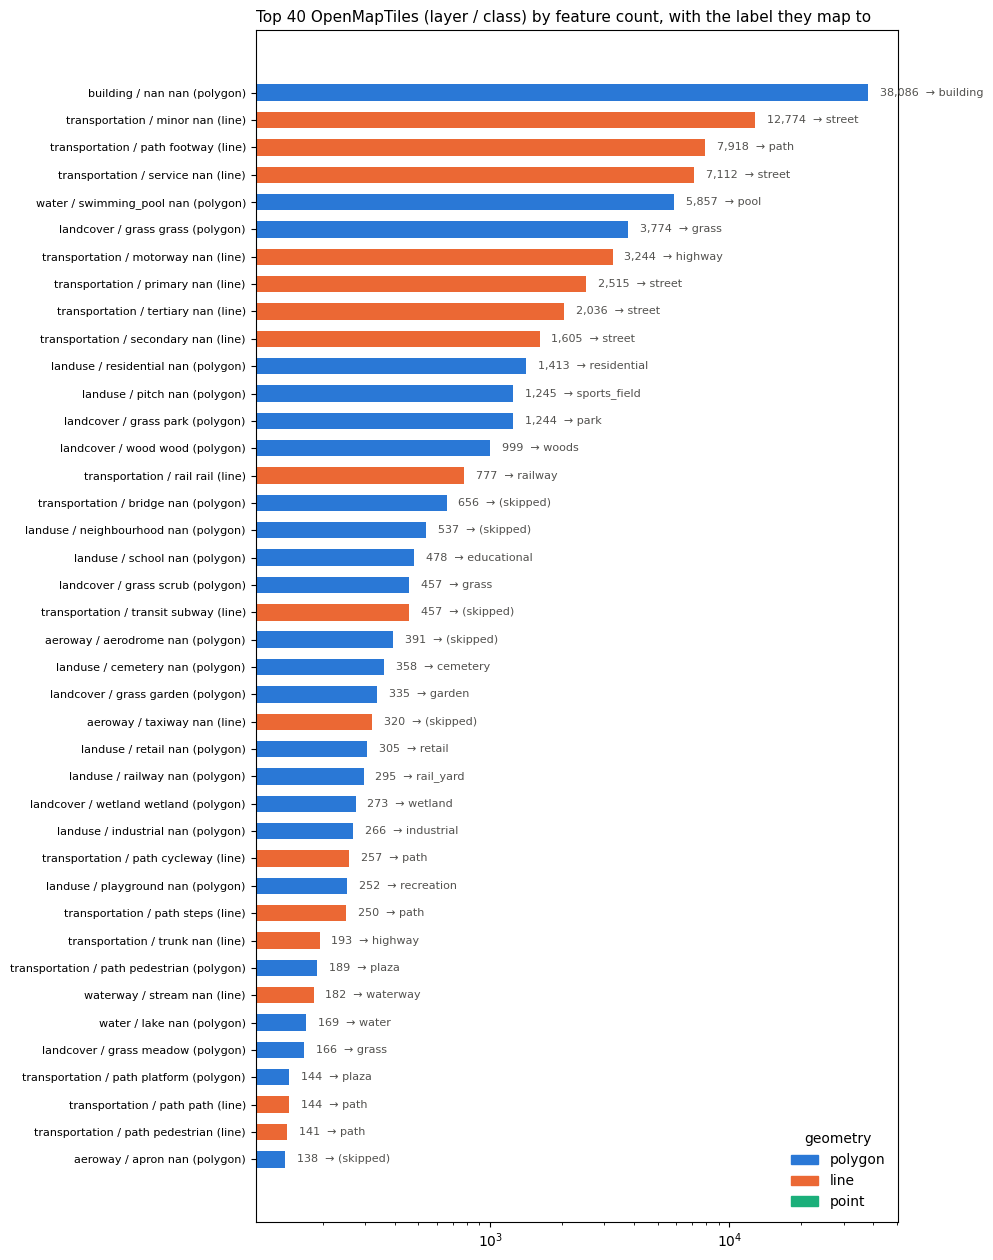

In [3]:
table_droplayer = table[table['layer']!='transportation_name']
top = table_droplayer.head(TOP_N).iloc[::-1]
names = [f"{l} / {c} {s} ({g})" for l, c, s, g in zip(top.layer, top["class"], top["subclass"], top.geom)]
fig, ax = plt.subplots(figsize=(10, 0.28 * len(top) + 1.5))
ax.barh(names, top.features, color=top.geom.map(GEOM_COLORS), height=0.6)
ax.set_xscale("log")
for y, (v, lab) in enumerate(zip(top.features, top.label)):
    ax.text(v * 1.12, y, f"{v:,}  → {lab}", va="center", fontsize=8, color="#52514e")
ax.tick_params(axis="y", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in GEOM_COLORS.values()]
ax.legend(handles, GEOM_COLORS.keys(), loc="lower right", frameon=False, title="geometry")
ax.set_title(f"Top {len(top)} OpenMapTiles (layer / class) by feature count, with the label they map to",
             loc="left", fontsize=11)
fig.tight_layout()

## How the render carto script renders each shape

In [4]:
import utils.render_carto as rc

rows = [("landcover/landuse", k, c, 1) for k, c in rc.AREA_COLORS.items() if c]
rows += [("water", "water", rc.WATER, 2), ("waterway", "waterway", rc.WATER, 3),
         ("building", "building", "#d9d0c9", 4), ("rail", "rail", "#707070", 17)]
rows += [("road", k, v[0], 8 + rc.ROAD_ORDER.index(k)) for k, v in rc.ROADS.items()]
rows += [("path", k, v[0], 7) for k, v in rc.PATH_STYLE.items()]
rows += [("boundary", "boundary", rc.BOUNDARY_COLOR, 6), ("park", "park", rc.PROTECTED_COLOR, 5),
         ("transportation", "track", "#996600", 7), ("transportation", "pedestrian", "#dddde8", 7)]
colors = pd.DataFrame(rows, columns=["layer", "class", "color", "zorder"]).sort_values("zorder")

shared = colors[colors.duplicated("color", keep=False)].groupby("color")["class"].apply(list)
shared

color
#008000                                    [park, bridleway]
#aad3df                                    [water, waterway]
#aae0cb                                       [pitch, track]
#add19e                                       [forest, wood]
#aedfa3                                  [orchard, vineyard]
#c7c7b4                           [construction, brownfield]
#cdebb0            [grass, grassland, meadow, village_green]
#ddecec                                       [ice, glacier]
#dffce2             [playground, stadium, recreation_ground]
#ebdbe8                                [railway, industrial]
#fa8072                         [steps, pedestrian, footway]
#ffffe5    [school, kindergarten, university, college, ho...
#ffffff                           [service, minor, tertiary]
Name: class, dtype: object

In [5]:
colors["layer"] = colors.layer.replace({"road": "transportation", "path": "transportation", "rail": "transportation",
                                        "landcover/landuse": "landcover,landuse"}).str.split(",")
colors = colors.explode("layer")
colors["class"] = colors["class"].mask(colors.color == "#dddde8", "pedestrian_area")

sub = ((table.layer == "landcover") & table.subclass.isin(rc.AREA_COLORS)) | ((table["class"] == "path") & table.subclass.isin(rc.PATH_STYLE))
key = table.subclass.where(sub, table["class"])
key = key.mask(table.layer.isin(["water", "waterway", "building", "boundary", "park"]), table.layer)
key = key.mask((table.subclass == "pedestrian") & (table.geom == "polygon"), "pedestrian_area")
m = table.assign(key=key).merge(colors.rename(columns={"class": "key"}), on=["layer", "key"]) #  how="left"
m.to_csv("label_colors.csv")

In [6]:
m.shape

(72, 11)

### Iterate through all annotated data

In [13]:
import json
from pathlib import Path
import pandas as pd

DATA = Path("../data/coco_osm_fixed")

rows = []
for split in ["train", "val", "test"]:
    d = json.load(open(DATA / "annotations" / f"{split}.json"))
    names = {c["id"]: c["name"] for c in d["categories"]}
    for a in d["annotations"]:
        rows.append({"split": split, "label": names[a["category_id"]], "geom": a.get("geom_type"),
                     "image": a["image_id"], "area": a["area"]})
# produce dataframe of all annoattions
ann = pd.DataFrame(rows)

# one row per label: annotations per split, images containing it, geometry types, median polygon area
# split by label
labels = (ann.pivot_table(index="label", columns="split", values="image", aggfunc="size", fill_value=0)
          [["train", "val", "test"]]
          .join(ann.groupby("label").agg(images=("image", "nunique"),
                                         geom=("geom", lambda g: ", ".join(sorted(set(g)))),
                                         median_area=("area", "median")))
          .sort_values("train", ascending=False))
labels["geom_mixed"] = labels.geom.str.contains(",")  # a label used for both polygons and lines
labels

,train,val,test,images,geom,median_area,geom_mixed
label,,,,,,,
building,156122,19047,12654,3587,polygon,1335.289336,False
path,41238,5093,5316,3536,line,0.000000,False
street,22635,2796,2698,3813,line,0.000000,False
pool,3055,395,209,1449,polygon,266.764455,False
grass,2261,271,780,1063,polygon,8697.292242,False
railway,1833,208,64,307,line,0.000000,False
highway,1830,228,476,525,line,0.000000,False
residential,1422,147,21,1136,polygon,178091.356597,False
park,787,90,243,838,polygon,66648.236430,False


In [14]:
all_labels = set(names.values())
print("labels with no annotations:", sorted(all_labels - set(ann.label)))
print("labels missing from val/test:", labels[(labels.val == 0) | (labels.test == 0)].index.tolist())
print("labels used as both polygon and line:", labels[labels.geom_mixed].index.tolist())
print("unknown annotations:", int(ann.label.str.startswith("unknown").sum()))

labels with no annotations: ['unknown', 'unknown_line']
labels missing from val/test: ['retail', 'bus_station', 'farm', 'garage']
labels used as both polygon and line: []
unknown annotations: 0


In [19]:
import gzip, json, glob, collections
import numpy as np, shapely, geopandas as gpd
from shapely.geometry import shape

def check(path):
    """Counts of copies and pieces per layer in one crop's GeoJSON (polygons only, as saved)."""
    d = json.load(gzip.open(path, "rt"))
    rows = [(x["properties"]["omt_layer"], f'{x["properties"].get("class")}/{x["properties"].get("subclass")}', p)
            for x in d["features"] if "Polygon" in x["geometry"]["type"]
            for p in shapely.get_parts(shape(x["geometry"]))]  # one row per polygon
    out = collections.Counter()
    if not rows:
        return out
    layer, kind, g = map(np.array, zip(*rows))
    g = gpd.GeoSeries(shapely.make_valid(g), crs=4326).to_crs(3857).values  # meters, like osm_crops.py

    # copies: identical shapes on a 1 cm grid (counts every repeat after the first)
    key = gpd.GeoSeries(g).set_precision(0.01, mode="pointwise").normalize().to_wkb()
    copy = pd.DataFrame({"layer": layer, "key": key}).duplicated().to_numpy()
    for l in layer[copy]:
        out[("copy", l)] += 1

    # pieces: >80% inside a larger shape of the same layer, class and subclass
    a = shapely.area(g)
    i, j = shapely.STRtree(g).query(g, predicate="intersects")
    piece = ((i != j) & (layer[i] == layer[j]) & (kind[i] == kind[j]) & (a[i] < a[j])
             & (shapely.area(shapely.intersection(g[i], g[j])) > 0.8 * a[i]))
    for k in np.unique(i[piece]):
        out[("piece", layer[k])] += 1
    return out

for folder in ["crops_flushing", "crops_flushing_fixed"]:
    total = collections.Counter()
    for f in sorted(glob.glob(f"../{folder}/*.geojson.gz")):
        total.update(check(f))
    print(folder, dict(total.most_common()))

crops_flushing {}
crops_flushing_fixed {('copy', 'landcover'): 50, ('copy', 'park'): 24, ('copy', 'aeroway'): 18, ('copy', 'landuse'): 18, ('copy', 'water'): 14, ('piece', 'building'): 6, ('piece', 'transportation'): 1, ('piece', 'landuse'): 1}


In [25]:
import sys, gzip, json, io, contextlib
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image

sys.path[:0] = ["../data_preprocess", "../utils"]
with contextlib.redirect_stdout(io.StringIO()):
    import create_coco_osm as cc
import render_carto as rc

key = lambda x: (x["properties"]["omt_layer"], x["properties"].get("class"), x["properties"].get("subclass"),
                 "point" if "Point" in x["geometry"]["type"] else "line" if "Line" in x["geometry"]["type"] else "polygon")

def png(d, name):  # render a GeoJSON dict, return its pixels
    json.dump(d, gzip.open(f"/tmp/{name}.geojson.gz", "wt"))
    rc.render(f"/tmp/{name}.geojson.gz", f"/tmp/{name}.png", 18, 2)
    return np.asarray(Image.open(f"/tmp/{name}.png").convert("RGB"))

first = {}  # feature type -> first crop where it reaches into the image
for f in sorted(Path("../crops_flushing_fixed").glob("*.geojson.gz")):
    d = json.load(gzip.open(f, "rt")); img = box(*d["bbox"])
    for x in d["features"]:
        if key(x) not in first and shape(x["geometry"]).intersects(img):
            first[key(x)] = f

rows = []
for k, f in first.items():
    layer, cls, sub, geom = k
    skipped = geom == "point" or (layer, cls) in cc.SKIP or (layer, "*") in cc.SKIP
    d = json.load(gzip.open(f, "rt"))
    drawn = (png(d, "a") != png(dict(d, features=[x for x in d["features"] if key(x) != k]), "b")).any()
    rows.append({"type": k, "label": None if skipped else cc.label_for(*k), "drawn": drawn, "crop": f.name})
t = pd.DataFrame(rows)

print("Labeled but not drawn:"); display(t[t.label.notna() & ~t.drawn])
print("Drawn but not labeled:"); display(t[t.label.isna() & t.drawn])

Labeled but not drawn:


,type,label,drawn,crop
24,"(landuse, playground, None, polygon)",recreation,False,flushing_04505.geojson.gz
62,"(transportation, path, platform, polygon)",plaza,False,flushing_04619.geojson.gz
95,"(transportation, path, footway, polygon)",plaza,False,queens_00636.geojson.gz


Drawn but not labeled:


,type,label,drawn,crop
3,"(transportation_name, minor, None, line)",None,True,flushing_04501.geojson.gz
6,"(transportation_name, tertiary, None, line)",None,True,flushing_04502.geojson.gz
11,"(transportation_name, motorway, None, line)",None,True,flushing_04503.geojson.gz
18,"(transportation_name, primary, None, line)",None,True,flushing_04504.geojson.gz
29,"(transportation_name, secondary, None, line)",None,True,flushing_04512.geojson.gz
45,"(place, neighbourhood, None, point)",None,True,flushing_04533.geojson.gz
60,"(place, quarter, None, point)",None,True,flushing_04610.geojson.gz
70,"(poi, railway, station, point)",None,True,flushing_04813.geojson.gz
71,"(poi, railway, subway, point)",None,True,flushing_04817.geojson.gz
78,"(transportation_name, trunk, None, line)",None,True,queens_00019.geojson.gz


In [34]:
import json, gzip, sys, numpy as np
sys.path.insert(0, "utils")
from render_carto import pixel_window

SPLIT, NAME = "train", "queens_03404"
coco = json.load(open(f"../data/coco_osm_fixed_2pxbuff/annotations/{SPLIT}.json"))
names = {c["id"]: c["name"] for c in coco["categories"]}
img = next(i for i in coco["images"] if i["file_name"] == f"{NAME}.png")
crop = json.load(gzip.open(f"../crops_flushing_fixed/{NAME}.geojson.gz", "rt"))

zoom = crop["metadata"]["camera_zoom"]
x0, y0, x1, _ = pixel_window(crop["bbox"], zoom)
scale = img["width"] / (x1 - x0)  # image pixels per zoom-18 pixel (2)
n = 256 * 2 ** zoom               # world width in zoom-18 pixels

def to_lonlat(pts):  # inverse of create_coco_osm.make_to_px
    px, py = pts[:, 0] / scale + x0, pts[:, 1] / scale + y0
    return np.column_stack([px / n * 360 - 180, np.degrees(np.arctan(np.sinh(np.pi * (1 - 2 * py / n)))) ]).tolist()

features = []
for a in coco["annotations"]:
    if a["image_id"] != img["id"]:
        continue
    pts = to_lonlat(np.reshape(a["segmentation"][0], (-1, 2)))
    geom = ({"type": "LineString", "coordinates": pts} if a.get("geom_type") == "line"
            else {"type": "Polygon", "coordinates": [pts + pts[:1]]})  # close the ring
    features.append({"type": "Feature", "geometry": geom, "properties": {"label": names[a["category_id"]], "id": a["id"]}})

json.dump({"type": "FeatureCollection", "features": features}, open(f"{NAME}_annotations_buff2.geojson", "w"))
print(len(features), "annotations ->", f"{NAME}_annotations.geojson")

32 annotations -> queens_03404_annotations.geojson
